# Parallel execution and memory

This 2.0.0 example prepares DuckDB inputs from Pandas, compares native/memmap training and prediction, retains a monitored report, and reads a few rows from file-backed ensemble output. It uses bundled bird observations, three ensembles and two workers. Install `stemflow[monitoring]` plus the notebook tools listed in the [examples overview](index.md).

The held-out split checks execution equivalence, not spatial generalization or calibration quality. Timings and sampled memory are illustrative measurements from this run. The benchmark section retains separately dated historical results with their own baseline definitions.

In [1]:
from pathlib import Path
import gc
import json
import pickle
import platform
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.tree import DecisionTreeClassifier

import stemflow
from stemflow.lazyloading import make_training_databases, make_duckdb_database
from stemflow.model.AdaSTEM import AdaSTEMClassifier

print("stemflow", stemflow.__version__, "Python", platform.python_version())
print(platform.platform())
from matplotlib import font_manager
try:
    font_manager.findfont("Arial", fallback_to_default=False)
    plt.rcParams["font.family"] = "Arial"
    print("Plot font: Arial")
except ValueError:
    print("Arial is unavailable; install it to reproduce the reference typography. Using the local Matplotlib default.")
plt.rcParams.update({"font.size": 12, "axes.labelsize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "pdf.fonttype": 42, "svg.fonttype": "none"})

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "docs/mini_data/mini_data.pkl").exists())
with (ROOT / "docs/mini_data/mini_data.pkl").open("rb") as handle:
    observations = pickle.load(handle).sample(8000, random_state=42)
features = ["longitude", "latitude", "DOY", "duration_minutes",
            "time_observation_started_minute_of_day", "elevation_mean", "bio1"]
X = observations[features].fillna(-1).copy()
y = (observations["count"] > 0).astype("int8").rename("occurrence")
del observations
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training rows: {len(X_train):,}; held-out rows: {len(X_test):,}")
print(f"Training detections: {int(y_train.sum()):,}")


stemflow 2.0.0 Python 3.13.15
macOS-27.0.1-arm64-arm-64bit-Mach-O
Plot font: Arial
Training rows: 6,400; held-out rows: 1,600
Training detections: 784


## Prepare inputs and compare execution

The helpers supply IDs and align labels. Native and memmap training use identical data, estimator settings and seeds. Each fitted model is predicted with both backends and checked for matching means, standard deviations and coverage. The native streaming reducer is also compared with its matrix route.

One monitor context covers fitting and all prediction calls, so its sampled peak includes the separate-output demonstration. The report remains on the model after leaving the context. The table reports **summed process-tree RSS**, which can count shared pages more than once. These samples are not a Slurm allocation or an exact peak guarantee.

The example retains small source frames; release unneeded frames after preparing a large real dataset. All scratch databases, models and maps are removed when the temporary context exits.

In [2]:
results, predictions, reports, prediction_details = [], {}, {}, {}
with tempfile.TemporaryDirectory(prefix="stemflow_example_") as scratch:
    X_path, y_path = make_training_databases(X_train, y_train, Path(scratch) / "training")
    test_path = make_duckdb_database(X_test, Path(scratch) / "test.duckdb")
    for backend in ["native", "memmap"]:
        model = AdaSTEMClassifier(
            base_model=DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42),
            ensemble_fold=3, min_ensemble_required=2,
            grid_len_upper_threshold=40, grid_len_lower_threshold=5,
            points_lower_threshold=100,
            temporal_start=1, temporal_end=366, temporal_step=60, temporal_bin_interval=80,
            n_jobs=2, random_state=42, sample_weights_for_classifier=False,
            lazy_loading=True, lazy_loading_dir=str(Path(scratch) / backend),
            save_gridding_plot=False, verbosity=0,
        )
        with model.monitor_execution(sample_interval=0.1, log_interval=None) as monitor:
            started = time.perf_counter()
            model.fit(X_path, y_path, training_data_backend=backend,
                      temporal_window_prequery=True, inner_max_num_threads=1,
                      max_concurrent_ensembles=2, persist_prediction_state=False)
            fit_seconds = time.perf_counter() - started
            started = time.perf_counter()
            native, native_std = model.predict_proba(test_path, temporal_window_prequery=True,
                prediction_backend="native", n_jobs=2, return_std=True)
            native_seconds = time.perf_counter() - started
            native_info = model.prediction_execution_info_.copy()
            started = time.perf_counter()
            mapped, mapped_std = model.predict_proba(test_path, temporal_window_prequery=True,
                prediction_backend="memmap", n_jobs=2, return_std=True)
            mapped_seconds = time.perf_counter() - started
            prediction_details[backend] = dict(native=native_info,
                memmap=model.prediction_execution_info_.copy())
            np.testing.assert_allclose(native, mapped, atol=1e-12, rtol=0, equal_nan=True)
            np.testing.assert_allclose(native_std, mapped_std, atol=1e-12, rtol=0, equal_nan=True)
            matrix_mean, matrix_std = model.predict_proba(test_path,
                temporal_window_prequery=True, streaming=False, return_std=True, n_jobs=2)
            np.testing.assert_allclose(native, matrix_mean, atol=1e-12, equal_nan=True)
            np.testing.assert_allclose(native_std, matrix_std, atol=1e-12, equal_nan=True)
            if backend == "memmap":
                separate = model.predict_proba(test_path, n_jobs=2,
                    temporal_window_prequery=True, prediction_backend="memmap",
                    return_by_separate_ensembles=True,
                    prediction_output_path=str(Path(scratch) / "ensemble_predictions.npy"))
                assert isinstance(separate, np.memmap)
                assert separate.shape == (len(X_test), model.ensemble_fold)
                ensemble_preview = pd.DataFrame(np.array(separate[:5], copy=True),
                    columns=[f"ensemble_{i}" for i in range(model.ensemble_fold)])
                separate.flush()
                del separate
                gc.collect()
        report = model.execution_monitor_
        assert not report["running"] and report["error"] is None
        reports[backend] = report
        predictions[backend] = mapped[:, 1]
        valid = np.isfinite(mapped[:, 1])
        rss = report["peak_tree_rss_bytes"]
        results.append(dict(backend=backend, fit_seconds=fit_seconds,
            native_prediction_seconds=native_seconds, memmap_prediction_seconds=mapped_seconds,
            coverage=float(valid.mean()), AUC=roc_auc_score(y_test.to_numpy()[valid], mapped[valid, 1]),
            Brier=brier_score_loss(y_test.to_numpy()[valid], mapped[valid, 1]),
            sampled_tree_RSS_MiB=rss / 1024**2 if rss is not None else np.nan,
            shared_file_MiB=model.execution_info_["shared_input_bytes"] / 1024**2))
        del model
        gc.collect()

table = pd.DataFrame(results).set_index("backend")
display(table.round(5))
np.testing.assert_allclose(predictions["native"], predictions["memmap"],
                           atol=1e-12, rtol=0, equal_nan=True)
assert not Path(scratch).exists()
print("Backend means/std and missing masks agree; scratch files removed.")
print("Stored monitor stages:", len(reports["memmap"]["stages"]))
display(ensemble_preview)


Backend means/std and missing masks agree; scratch files removed.
Stored monitor stages: 25


/private/tmp/stemflow_ci_fix_20261028/stemflow/model/AdaSTEM.py:1061: UserWarning: There are 10.7% points (171 points) falling out of predictable range.
  warnings.warn(f"There are {100 * missing / len(mean):.3g}% points ({missing} points) falling out of predictable range.")
/private/tmp/stemflow_ci_fix_20261028/stemflow/lazyloading/shared_prediction.py:396: UserWarning: There are 10.7% points (171 points) falling out of predictable range.
  warnings.warn(f'There are {100 * missing / len(mean):.3g}% points ({missing} points) '
/private/tmp/stemflow_ci_fix_20261028/stemflow/model/AdaSTEM.py:1255: UserWarning: There are 0.106875% points (171 points) falling out of predictable range.
  warnings.warn(f"There are {nan_frac}% points ({nan_count} points) falling out of predictable range.")
/private/tmp/stemflow_ci_fix_20261028/stemflow/model/AdaSTEM.py:1061: UserWarning: There are 10.7% points (171 points) falling out of predictable range.
  warnings.warn(f"There are {100 * missing / len(mean

,fit_seconds,native_prediction_seconds,memmap_prediction_seconds,coverage,AUC,Brier,sampled_tree_RSS_MiB,shared_file_MiB
backend,,,,,,,,
native,2.56123,1.57563,1.66858,0.89312,0.70569,0.10353,872.76562,0.00000
memmap,2.61495,1.59866,1.67083,0.89312,0.70569,0.10353,882.90625,0.22656


,ensemble_0,ensemble_1,ensemble_2
0,0.150000,0.1,0.189820
1,0.027027,0.1,0.076923
2,0.033333,0.1,0.208333
3,0.020833,0.0,0.089888
4,0.150602,0.0,0.140000


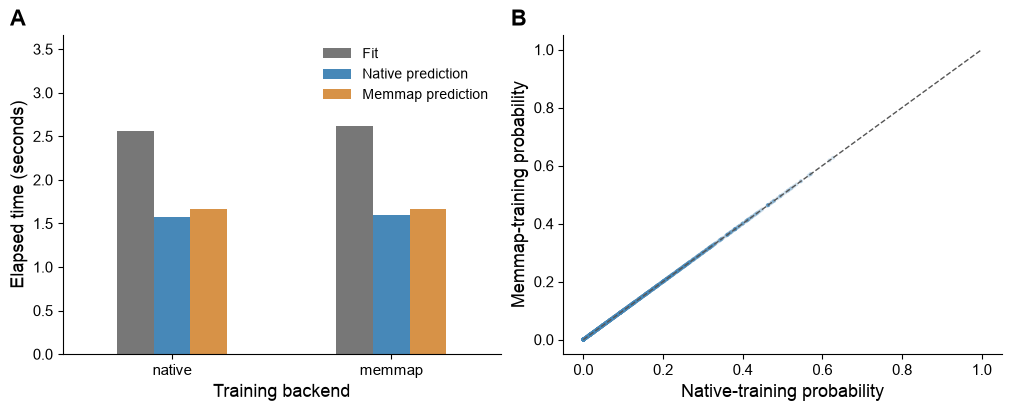

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
runtime = table[["fit_seconds", "native_prediction_seconds", "memmap_prediction_seconds"]].copy()
runtime.columns = ["Fit", "Native prediction", "Memmap prediction"]
runtime.plot.bar(ax=axes[0], rot=0, color=["#777777", "#4788B8", "#D79247"])
axes[0].set(xlabel="Training backend", ylabel="Elapsed time (seconds)")
axes[0].set_ylim(0, runtime.to_numpy().max() * 1.4)
axes[0].legend(frameon=False)
a, b = predictions["native"], predictions["memmap"]
valid = np.isfinite(a) & np.isfinite(b)
axes[1].scatter(a[valid], b[valid], s=8, alpha=0.25, color="#4788B8", edgecolors="none")
axes[1].plot([0, 1], [0, 1], color="#555555", linestyle="--", linewidth=1)
axes[1].set(xlabel="Native-training probability", ylabel="Memmap-training probability")
for letter, ax in zip("AB", axes):
    ax.text(-0.12, 1.03, letter, transform=ax.transAxes, fontsize=16, fontweight="bold")
plt.show()


## Historical complete-job benchmarks

The saved table below comes from the separately recorded baseline/rewrite runs; it is not recomputed by executing this notebook. The baseline merges the then-current main and community branches before execution optimization. Each case used identical input/model settings and included preparation, fitting and prediction. See [benchmark definitions and limitations](https://github.com/chenyangkang/stemflow/blob/codex-rewrite/resources/REWRITE.md).

The newly measured table above is a small demonstration, not a performance comparison against untouched main. RSS, macOS physical footprint and scheduler/cgroup accounting differ. Map file size and serialized model size are logical payloads, not additive components of resident memory.

In [4]:
summary_path = ROOT / "data/00_benchmarks/summary.json"
if summary_path.exists():
    benchmark = pd.DataFrame(json.loads(summary_path.read_text()))
    selected = ["case", "variant", "wall_seconds", "fit_seconds", "prediction_seconds",
                "peak_accounted_mb", "peak_rss_mb", "saved_models_mb", "shared_file_mb"]
    display(benchmark[selected].round(2))
    assert benchmark.same_nan_mask.all() and benchmark.same_full_nan_mask.all()
    assert benchmark.max_prediction_difference.max() == 0
    assert benchmark.max_full_prediction_difference.max() == 0
else:
    print("Run scripts/00_benchmarks/run_matrix.py and summarize_results.py for historical-style benchmark results.")


,case,variant,wall_seconds,fit_seconds,prediction_seconds,peak_accounted_mb,peak_rss_mb,saved_models_mb,shared_file_mb
0,acadian_100000_e4,baseline,16.36,2.48,1.69,1351.17,2648.30,1.87,0.00
1,acadian_100000_e4,rewrite_native,16.20,2.43,1.66,1310.39,2516.28,1.87,0.00
2,acadian_100000_e4,rewrite_memmap,16.34,2.65,1.62,1162.88,2434.98,1.87,36.35
3,acadian_100000_e8,baseline,18.11,3.56,2.02,1363.19,3053.41,3.87,0.00
4,acadian_100000_e8,rewrite_native,17.88,3.51,1.90,1314.88,2945.16,3.87,0.00
5,acadian_100000_e8,rewrite_memmap,17.81,3.65,1.91,1156.42,2814.92,3.87,36.35
6,acadian_100000_e8_j2,baseline,21.10,5.53,2.37,864.89,2082.23,3.87,0.00
7,acadian_100000_e8_j2,rewrite_native,20.53,5.33,2.43,814.14,2007.69,3.87,0.00
8,acadian_100000_e8_j2,rewrite_memmap,20.29,5.47,2.14,712.46,1787.77,3.87,36.35
9,acadian_30000_e4,baseline,15.26,2.26,1.66,720.84,1275.81,1.44,0.00


## Apply the controls to a larger job

`ensemble_fold` chooses ensemble count. `max_concurrent_ensembles` caps partitioning/training workers, and prediction's `n_jobs` is independent. Set base-estimator threads explicitly. `max_mem` limits DuckDB buffers, not total memory or estimator workspace.

Memmap prediction shares numeric input and bounds pending result buffers. Separate ensemble output still needs rows × ensembles storage. The file-backed example above copied only five rows for display; avoid `np.array(full_matrix)` in a large workflow. The caller owns its output file; this example intentionally places it in scratch.

Use native execution for SphereAdaSTEM and unsupported custom overrides. Notebook pages 01–09 retain historical outputs and need their original external datasets for a full rerun. See the [overview](index.md), [execution API](../API_Documentation/model/stemflow.model.AdaSTEM.md), [monitor API](../API_Documentation/utils/stemflow.utils.execution_monitor.md), and [execution guide](../Tips/Tips_for_parallel_execution.md).